<a id="chapter-04"></a>

# Chapter 04 · The Cross-Entropy Method / 交叉熵方法

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解无梯度规划式的 elite 筛选
- 把 episode 回报转成监督学习数据
- 认识 CEM 在稀疏奖励下的局限

**开始前最好已经会：**

- 理解 episode 与 episode return
- 会读分类交叉熵
- 知道 percentile/分位数


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Taxonomy of RL methods | 心智模型与章节连接 | 概览 |
| CEM in practice | 最大似然推导 | 详细 |
| CEM on CartPole | 算法流程、源码路线 | 详细 |
| CEM on FrozenLake | 失败原因、改进与源码路线 | 详细 |
| Theoretical background | elite MLE / 交叉熵解释 | 主线 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

如果我们暂时不会计算策略梯度，能不能只模仿自己表现最好的那些轨迹？CEM 就是这个朴素想法的系统版本。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

采样一批 episode → 按回报选前若干百分位 → 用 elite 的 `(state, action)` 做分类训练 → 重复。这里的“交叉熵”指分类损失，不是直接计算策略梯度。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\tau$ | 一条完整轨迹 | 状态、动作、奖励序列 |
| $R(\tau)$ | 轨迹总回报 | 用于给 episode 排名 |
| $q_\rho$ | $\rho$ 分位阈值 | 决定谁是 elite |
| $E$ | elite 轨迹集合 | 高于阈值的样本 |
| $\pi_\theta(a\mid s)$ | 待训练的分类策略 | 输出动作概率 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 把好轨迹变成监督数据

采样 batch $\{\tau_i\}$，选择回报达到分位阈值的集合：

$$E=\{\tau_i:R(\tau_i)\ge q_\rho\}$$

我们希望新策略提高 elite 中动作的似然：

$$\max_\theta\prod_{(s,a)\in E}\pi_\theta(a|s)$$

乘积容易数值下溢，取对数把乘积变成求和：

$$\max_\theta\sum_{(s,a)\in E}\log\pi_\theta(a|s)$$

优化器通常做最小化，于是加负号：

$$\boxed{L=-\frac1{|E|}\sum_{(s,a)\in E}\log\pi_\theta(a|s)}$$

这恰好是多分类交叉熵。

### 2. 为什么可能学不动

若所有轨迹回报都相同，elite 与普通样本没有区别；若成功极少，batch 里可能一个成功样本也没有。CEM 依赖“一个 batch 内已经出现可区分的好行为”。


## 4. 手算一个最小例子


回报 `[3,10,6,1,8]` 的 70 分位阈值约为 7.6，因此只有回报 10 和 8 的 episode 进入 elite。假设它们共提供 4 个 `(state, action)`，交叉熵只在这 4 个动作上训练。

思考：若把分位数提高到 95，可能只剩一个 episode，梯度方差会变大；降到 20，则大量平庸动作被当成正确标签。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Elite 筛选与分类目标

阈值 $q$ 是 batch 回报的百分位数；elite 集合 $E=\{\tau_i:R(\tau_i)\ge q\}$。

$$L(\theta)=-\frac1{|E|}\sum_{(s,a)\in E}\log\pi_\theta(a\mid s)$$

策略逐渐提高 elite 动作的概率。由于只看整条轨迹排名，奖励稀疏或 episode 很长时，信号会很弱。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $R(\tau_i)$ | `returns` | 每个 episode 一个标量 |
| $q_\rho$ | `np.percentile(returns, 70)` | elite 阈值 |
| $E$ | `elite_ids` | 满足阈值的轨迹索引 |
| 策略 logits | `logits`，shape `(samples, actions)` | 尚未 softmax 的动作分数 |
| $-\log\pi(a\mid s)$ | `F.cross_entropy(logits, actions)` | 稳定地完成 log-softmax + NLL |

**从公式过渡到代码时：**先用一个小 batch 看 percentile 怎样留下高回报样本，再计算分类损失。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np
import torch
import torch.nn.functional as F

returns = np.array([3, 10, 6, 1, 8], dtype=float)
threshold = np.percentile(returns, 70)
elite_ids = np.flatnonzero(returns >= threshold)
print("threshold:", threshold, "elite episodes:", elite_ids.tolist())

# 假设 elite 轨迹收集到 4 个状态，其正确动作是 actions。
logits = torch.tensor([[2., 0.], [0., 2.], [1., 0.], [0., 1.]], requires_grad=True)
actions = torch.tensor([0, 1, 0, 1])
loss = F.cross_entropy(logits, actions)
loss.backward()
print("loss:", loss.item(), "gradient shape:", tuple(logits.grad.shape))


threshold: 7.6 elite episodes: [1, 4]
loss: 0.22009484469890594 gradient shape: (4, 2)


### 怎样读运行结果

先确认 elite 索引是回报 10 和 8 对应的位置。梯度 shape 与 logits 相同；每行所选动作的梯度会推动该动作概率上升。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
repeat:
    batch = []
    while len(batch) < batch_size:
用当前策略采样完整 episode
保存每步 (observation, action) 和 episode return
    reward_bound = percentile(returns, percentile)
    elite = 所有 return >= reward_bound 的 episode
    states, actions = 展平 elite transitions
    loss = cross_entropy(policy(states), actions)
    更新策略
    若平均回报达到阈值则停止
```

FrozenLake 难点是成功轨迹稀少且随机转移使好动作标签含噪。书中版本通过 one-hot observation、折扣/保留 elite、非滑动环境等方式逐步诊断，而不是把失败简单归因于网络。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

returns = np.array([3., 10., 6., 1., 8.])
for percentile in (50, 70, 90):
    bound = np.percentile(returns, percentile)
    elite = returns[returns >= bound]
    print(percentile, "bound=", round(bound, 2), "elite=", elite.tolist())


50 bound= 6.0 elite= [10.0, 6.0, 8.0]
70 bound= 7.6 elite= [10.0, 8.0]
90 bound= 9.2 elite= [10.0]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_cartpole.py`](../../Chapter04/01_cartpole.py) | `iterate_batches`, `filter_batch` | 完整 CEM 数据生成与 elite 过滤 |
| [`02_frozenlake_naive.py`](../../Chapter04/02_frozenlake_naive.py) | naive baseline | 观察稀疏奖励为何失败 |
| [`03_frozenlake_tweaked.py`](../../Chapter04/03_frozenlake_tweaked.py) | 折扣/elite 改进 | 比较数据选择变化 |
| [`04_frozenlake_nonslippery.py`](../../Chapter04/04_frozenlake_nonslippery.py) | 非滑动环境 | 隔离环境随机性 |

<details>
<summary>为什么按这个顺序读</summary>

先精读 `EpisodeStep` 与 `Episode`，确认回报属于整条 episode，而监督标签属于每一步。再看 `filter_batch`：它先算 percentile，再把 elite 轨迹展平。最容易出现的 bug 是把每步 reward 当 episode return，或忘记把离散状态 one-hot 后输入线性层。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**CEM 策略选择最优动作的概率

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


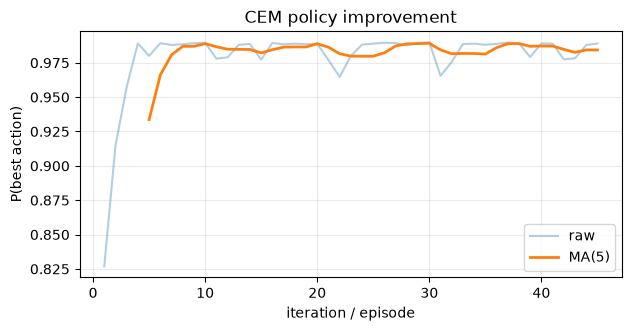

final action probabilities: [0.011 0.989]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(4)
true_rewards = np.array([0.25, 0.75])
logits = np.zeros(2)
history = []
for iteration in range(45):
    probs = np.exp(logits - logits.max()); probs /= probs.sum()
    actions = rng.choice(2, size=120, p=probs)
    rewards = (rng.random(120) < true_rewards[actions]).astype(float)
    elite = actions[rewards >= np.quantile(rewards, 0.7)]
    counts = np.bincount(elite, minlength=2) + 1.0  # smoothing 防止 log(0)
    logits = np.log(counts / counts.sum())
    history.append(np.exp(logits[1]) / np.exp(logits).sum())

plot_curve(history, "CEM policy improvement", "P(best action)", window=5)
print("final action probabilities:", np.round(np.exp(logits) / np.exp(logits).sum(), 3))


### 曲线怎么读

曲线总体应向 1 移动，但会因采样奖励上下波动。一次跌落不代表算法坏了；持续坍缩到错误动作才需要检查 elite 数量和样本量。

### 调参过程：一次只改变一个因素

- 先用较大 batch 保证 elite 中有信号。
- 在 60%～90% 间调整 percentile；越高选择压力越强、方差也越大。
- 困难环境保留多轮 elite 或对 episode 按折扣回报排序。

### 失败案例复盘

- percentile 太高导致 elite 几乎为空。
- 稀疏奖励下所有 episode 同分，CEM 没有学习信号。
- 只报告最好一次运行，没有跨随机种子比较。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- percentile 太高会导致样本过少，太低则学习信号不纯。
- 保留上一轮优秀轨迹能帮助稀疏奖励，但要避免数据越来越陈旧。
- 先用非滑动 FrozenLake 检查逻辑，再增加随机转移。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把 percentile 从 70 改为 50 和 90，观察 elite 数量；解释 batch 大小时阈值稳定性的差异。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

50 分位阈值为 6，保留 `[10,6,8]`；70 分位约 7.6，保留 `[10,8]`；90 分位约 9.2，只保留 `[10]`。batch 小时高分位会让样本量剧烈波动，因此应同时监控 elite 数量。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- CEM 把 RL 暂时转成 elite 行为的监督学习。
- 分位数控制样本质量与数量的平衡。
- 它适合短 episode、稠密反馈和容易偶然成功的任务。
- 稀疏奖励下可保留历史 elite 或改用更合适的 RL 方法。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么 CEM 的 loss 是交叉熵？分位数越高是否一定越好？

<details>
<summary>展开答案</summary>

因为它最大化 elite 动作在策略下的对数似然，与分类交叉熵等价。分位数过高会让样本过少、方差很大，因此不一定更好。
</details>


## 17. 与前后章节连接

第 5 章转向已知模型的动态规划；第 11 章会给出不依赖 hard elite 筛选的策略梯度。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

CEM 也可直接搜索参数分布：采样参数、评估、用 elite 重新估计均值和方差；这与第 17 章黑盒优化相呼应。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-04) · [← 学习索引](../README.md)
